# Notebook 06 — Diagnóstico dos cursos da PUC-Rio por área (CPC 2023)

**Objetivo:** para **cada curso da PUC-Rio**, comparar seus oito indicadores com:
1. a média dos **outros cursos da mesma área e do mesmo grupo** (C2, K=4);
2. a média dos **outros cursos da mesma área**, independentemente do grupo.

O agrupamento (clustering) é ajustado na **base completa de 2023**. A área é utilizada **depois**, para construir referências acadêmicas pertinentes. O próprio curso da PUC-Rio é excluído das duas médias.

Além dos gráficos comparativos, calculamos silhueta individual, distância ao centroide, contribuição dos indicadores e pares próximos. O C3 (K=4) permanece como análise de robustez. Não utilizamos PCA.


## 1. Configuração e leitura da base
Coloque este arquivo na pasta principal do projeto, junto de `dados/processados/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score
from sklearn.metrics import adjusted_rand_score
from scipy.optimize import linear_sum_assignment

SEMENTE = 42
N_INIT = 20
K = 4
CODIGO_IES_PUC = 528
N_VIZINHOS = 10
REPETICOES = 30
SALVAR_FIGURAS = True
PASTA_PROJETO = Path.cwd()
ARQUIVO = PASTA_PROJETO/'dados'/'processados'/'base_analitica_1907_cursos.csv'
if not ARQUIVO.exists():
    ARQUIVO = PASTA_PROJETO/'base_analitica_1907_cursos.csv'
if not ARQUIVO.exists():
    raise FileNotFoundError('CSV não encontrado. Coloque o notebook na pasta principal do projeto.')
SAIDA = PASTA_PROJETO/'resultados_notebook_06'/'BASE_COMPLETA'
SAIDA.mkdir(parents=True,exist_ok=True)
INDICADORES = ['Enade_2023','IDD_2023','Mestres_2023','Doutores_2023',
    'Regime_Trabalho_2023','Organizacao_Didatica_2023',
    'Infraestrutura_2023','Oportunidades_2023']
ROTULOS = ['ENADE','IDD','Mestres','Doutores','Regime de trabalho',
           'Organização didática','Infraestrutura','Oportunidades']
base = pd.read_csv(ARQUIVO,encoding='utf-8-sig')
base.columns = base.columns.str.replace('\ufeff','',regex=False).str.strip()
colunas = ['Código da IES','Código do Curso','Area_2023']+INDICADORES
assert set(colunas).issubset(base.columns), set(colunas)-set(base.columns)
for col in INDICADORES+['Código da IES','Código do Curso']:
    base[col] = pd.to_numeric(base[col],errors='coerce')
base = base.loc[np.isfinite(base[INDICADORES].to_numpy(float)).all(axis=1)].copy().reset_index(drop=True)
assert not base.duplicated(['Código da IES','Código do Curso']).any()
idx_puc = np.flatnonzero(base['Código da IES'].eq(CODIGO_IES_PUC).to_numpy())
assert len(idx_puc)>0,'Não foram encontrados cursos da PUC-Rio na base.'
print('Cursos elegíveis:',len(base),'| Áreas:',base['Area_2023'].nunique(),
      '| Cursos PUC-Rio:',len(idx_puc),'| Saída:',SAIDA)
display(base.loc[idx_puc,['Código do Curso','Area_2023','CPC_2023']].sort_values('Código do Curso'))

Cursos elegíveis: 1907 | Áreas: 10 | Cursos PUC-Rio: 8 | Saída: g:\Meu Drive\Mestrado _ Eng_Ind\IND2622 - Ciencia de dados para processos de negocios\Trabalho final - CPC (escolhido)\Projeto_CPC_PUC_Rio_2026\resultados_notebook_06\BASE_COMPLETA


,Código do Curso,Area_2023,CPC_2023
1139,23702,5902,3.812
435,29445,5710,3.760
801,29446,5806,3.382
985,32655,5814,2.707
1388,32975,6008,3.202
1550,44431,6208,3.176
133,59962,21,2.689
1784,70523,6307,2.814


## 2. Ajuste dos dois cenários na base completa
O escalonador é ajustado na base elegível de 2023. Isso é apropriado para **descrever os grupos finais**; a validação sob reamostragem foi tratada separadamente no 05.2. A numeração dos grupos é arbitrária.

In [2]:
def representar(df,cenario):
    if cenario == 'C2_8IND':
        return df[INDICADORES].copy()
    if cenario == 'C3_4DIM':
        return pd.DataFrame({
            'ENADE':df['Enade_2023'],
            'IDD':df['IDD_2023'],
            'Condicoes_Formacao':(7.5*df['Organizacao_Didatica_2023']+5*df['Infraestrutura_2023']+2.5*df['Oportunidades_2023'])/15,
            'Corpo_Docente':(7.5*df['Mestres_2023']+15*df['Doutores_2023']+7.5*df['Regime_Trabalho_2023'])/30
        },index=df.index)
    raise ValueError(cenario)

def ajustar_cenario(cenario):
    dados = representar(base,cenario)
    scaler = StandardScaler()
    X = scaler.fit_transform(dados)
    modelo = KMeans(n_clusters=K,random_state=SEMENTE,n_init=N_INIT).fit(X)
    labels = modelo.labels_
    sil = silhouette_samples(X,labels)
    distancias = np.linalg.norm(X-modelo.cluster_centers_[labels],axis=1)
    percentis = np.empty(len(base))
    for grupo in np.unique(labels):
        ix = np.flatnonzero(labels==grupo)
        percentis[ix] = pd.Series(distancias[ix]).rank(pct=True,method='average').to_numpy()*100
    return dict(cenario=cenario,dados=dados,scaler=scaler,X=X,modelo=modelo,
                labels=labels,sil=sil,dist=distancias,percentis=percentis)

CENARIOS = {c:ajustar_cenario(c) for c in ['C2_8IND','C3_4DIM']}
for nome,r in CENARIOS.items():
    print(nome,'| Silhueta geral:',round(silhouette_score(r['X'],r['labels']),4),
          '| Tamanhos:',dict(pd.Series(r['labels']).value_counts().sort_index()))

C2_8IND | Silhueta geral: 0.2388 | Tamanhos: {0: np.int64(574), 1: np.int64(437), 2: np.int64(611), 3: np.int64(285)}
C3_4DIM | Silhueta geral: 0.278 | Tamanhos: {0: np.int64(463), 1: np.int64(354), 2: np.int64(594), 3: np.int64(496)}


## 3. Tabela individual de enquadramento da PUC-Rio
**Percentil de distância alto:** o curso está mais distante do centroide que a maioria dos membros de seu grupo. **Silhueta individual próxima de zero:** o curso está perto da fronteira geométrica entre grupos. Valores negativos indicam possível maior proximidade média com outro grupo.

In [3]:
linhas=[]
for nome,r in CENARIOS.items():
    for i in idx_puc:
        linhas.append({'Cenario':nome,'Curso_PUC':int(base.loc[i,'Código do Curso']),
            'Area_2023':base.loc[i,'Area_2023'],
            'Grupo':int(r['labels'][i]),'N_grupo':int(np.sum(r['labels']==r['labels'][i])),
            'Silhueta_individual':float(r['sil'][i]),
            'Distancia_padronizada_centroide':float(r['dist'][i]),
            'Percentil_distancia_grupo':float(r['percentis'][i])})
diagnostico = pd.DataFrame(linhas).sort_values(['Curso_PUC','Cenario'])
diagnostico.to_csv(SAIDA/'diagnostico_enquadramento_PUCRio.csv',index=False,encoding='utf-8-sig')
display(diagnostico.round(3))

,Cenario,Curso_PUC,Area_2023,Grupo,N_grupo,Silhueta_individual,Distancia_padronizada_centroide,Percentil_distancia_grupo
4,C2_8IND,23702,5902,1,437,0.072,2.828,96.568
12,C3_4DIM,23702,5902,0,463,0.299,1.237,55.724
1,C2_8IND,29445,5710,1,437,0.124,2.491,92.220
9,C3_4DIM,29445,5710,0,463,0.327,1.020,36.717
2,C2_8IND,29446,5806,0,574,0.024,2.138,69.164
10,C3_4DIM,29446,5806,0,463,0.008,1.341,64.147
3,C2_8IND,32655,5814,2,611,0.085,2.555,87.889
11,C3_4DIM,32655,5814,2,594,0.312,0.922,25.926
5,C2_8IND,32975,6008,1,437,0.100,2.295,88.330
13,C3_4DIM,32975,6008,0,463,0.054,1.312,61.771


## 4. Perfis dos grupos: centroides em escala original
No C2, a média dos indicadores originais de cada grupo coincide com o centroide após transformação inversa. Para o C3, mostramos também os **oito indicadores originais por grupo**, para permitir comparações substantivas sem misturar escalas.

In [4]:
centroides=[]
for nome,r in CENARIOS.items():
    for grupo in range(K):
        membros=base.loc[r['labels']==grupo,INDICADORES]
        row={'Cenario':nome,'Grupo':grupo,'N':len(membros)}
        row.update(membros.mean().to_dict())
        centroides.append(row)
centroides=pd.DataFrame(centroides)
centroides.to_csv(SAIDA/'centroides_8_indicadores.csv',index=False,encoding='utf-8-sig')
display(centroides.round(3))

,Cenario,Grupo,N,Enade_2023,IDD_2023,Mestres_2023,Doutores_2023,Regime_Trabalho_2023,Organizacao_Didatica_2023,Infraestrutura_2023,Oportunidades_2023
0,C2_8IND,0,574,2.400,2.573,4.517,2.842,4.031,4.046,4.259,4.120
1,C2_8IND,1,437,3.777,3.632,4.689,4.026,4.872,2.276,2.597,3.104
2,C2_8IND,2,611,1.937,1.779,4.524,3.449,4.299,2.239,2.434,2.323
3,C2_8IND,3,285,1.967,2.153,2.328,1.322,2.786,2.882,2.935,2.682
4,C3_4DIM,0,463,3.771,3.680,4.658,3.955,4.809,2.343,2.651,3.109
5,C3_4DIM,1,354,1.911,2.043,2.741,1.345,2.852,2.926,3.030,2.788
6,C3_4DIM,2,594,1.916,1.730,4.552,3.605,4.358,2.291,2.499,2.430
7,C3_4DIM,3,496,2.442,2.641,4.514,2.877,4.110,4.083,4.272,4.103


## 5. Referências comparáveis: PUC-Rio × mesma área e grupo × mesma área

**Regra principal:** não utilizar a média de cursos de áreas diferentes no gráfico comparativo. A referência de pares é a interseção entre **área do curso** e **grupo do curso**, excluindo o próprio curso da PUC-Rio.

Se não houver outros cursos nessa interseção, a referência fica indisponível (sem substituir silenciosamente por outra média). As contagens são exibidas nos gráficos.


In [5]:
def referencias_curso(i, cenario='C2_8IND'):
    r = CENARIOS[cenario]
    grupo = r['labels'][i]
    area = base.loc[i, 'Area_2023']
    mask_area = base['Area_2023'].eq(area).to_numpy()
    mask_grupo = r['labels'] == grupo
    outros = np.arange(len(base)) != i
    pares = mask_area & mask_grupo & outros
    area_outros = mask_area & outros
    series = {
        'PUC-Rio': base.loc[i, INDICADORES].astype(float),
        'Mesma área e grupo': base.loc[pares, INDICADORES].mean() if pares.sum() else pd.Series(np.nan, index=INDICADORES),
        'Média da área': base.loc[area_outros, INDICADORES].mean() if area_outros.sum() else pd.Series(np.nan, index=INDICADORES)
    }
    tamanhos = {'Mesma área e grupo': int(pares.sum()), 'Média da área': int(area_outros.sum())}
    return pd.DataFrame(series), tamanhos

exemplo = int(idx_puc[0])
ref, ns = referencias_curso(exemplo)
print('Exemplo: curso', int(base.loc[exemplo, 'Código do Curso']),
      '| Área:', base.loc[exemplo, 'Area_2023'], '| Grupo:', CENARIOS['C2_8IND']['labels'][exemplo])
print('Quantidade de outros cursos:', ns)
display(ref.round(3))


Exemplo: curso 59962 | Área: 21 | Grupo: 3
Quantidade de outros cursos: {'Mesma área e grupo': 54, 'Média da área': 265}


,PUC-Rio,Mesma área e grupo,Média da área
Enade_2023,3.531,2.242,2.707
IDD_2023,2.358,2.396,2.801
Mestres_2023,3.941,2.451,4.148
Doutores_2023,2.529,1.258,2.629
Regime_Trabalho_2023,0.000,2.600,3.887
Organizacao_Didatica_2023,2.734,2.724,2.859
Infraestrutura_2023,3.780,2.981,3.060
Oportunidades_2023,3.537,2.918,3.190


## 6. Pares estatisticamente próximos
Calculamos distância euclidiana nos **oito indicadores padronizados** do C2. O conjunto de vizinhos é definido dentro da **mesma área**, preferencialmente no **mesmo grupo**. Se houver menos de `N_VIZINHOS` candidatos no cruzamento área ∩ grupo, mostramos os disponíveis e, em separado, os vizinhos da mesma área independentemente do grupo. Não se deve confundir proximidade estatística com equivalência institucional.

In [6]:
def vizinhos(i,n=N_VIZINHOS,mesmo_grupo=True):
    r=CENARIOS['C2_8IND']
    area=base.loc[i,'Area_2023']
    mask=base['Area_2023'].eq(area).to_numpy() & (np.arange(len(base))!=i)
    if mesmo_grupo:
        mask &= r['labels']==r['labels'][i]
    candidatos=np.flatnonzero(mask)
    dist=np.linalg.norm(r['X'][candidatos]-r['X'][i],axis=1)
    ordem=np.argsort(dist)[:n]
    ids=candidatos[ordem]
    tab=base.loc[ids,['Código da IES','Código do Curso','Area_2023']+INDICADORES].copy()
    tab.insert(3,'Distancia_padronizada_C2',dist[ordem])
    return tab.reset_index(drop=True)

print('Pares dentro da área e do grupo:')
display(vizinhos(exemplo).iloc[:,:4])
print('Pares dentro da área, independentemente do grupo:')
display(vizinhos(exemplo,mesmo_grupo=False).iloc[:,:4])

Pares dentro da área e do grupo:


,Código da IES,Código do Curso,Area_2023,Distancia_padronizada_C2
0,402,21538,21,1.520713
1,423,1126141,21,1.891780
2,1060,1179176,21,1.990775
3,2183,1287486,21,2.026373
4,76,3681,21,2.181949
5,402,1282869,21,2.284574
6,146,20300,21,2.657946
7,1494,1158692,21,2.691769
8,1961,90778,21,2.754445
9,337,86577,21,2.822629


Pares dentro da área, independentemente do grupo:


,Código da IES,Código do Curso,Area_2023,Distancia_padronizada_C2
0,402,21538,21,1.520713
1,423,1126141,21,1.891780
2,1060,1179176,21,1.990775
3,2183,1287486,21,2.026373
4,11,52971,21,2.028177
5,275,6574,21,2.058801
6,3985,1112150,21,2.067755
7,76,3681,21,2.181949
8,3631,83426,21,2.262036
9,402,1282869,21,2.284574


## 7. Gráficos por curso da PUC-Rio

O **gráfico principal** possui apenas três séries: **PUC-Rio**, **outros cursos da mesma área e grupo** e **outros cursos da mesma área**. Ele é gerado automaticamente para **todos os cursos da PUC-Rio**.

Os gráficos complementares mostram a diferença em relação aos pares da mesma área e grupo, a posição relativa à distância ao centroide (estrela) e a contribuição de cada indicador para essa distância.


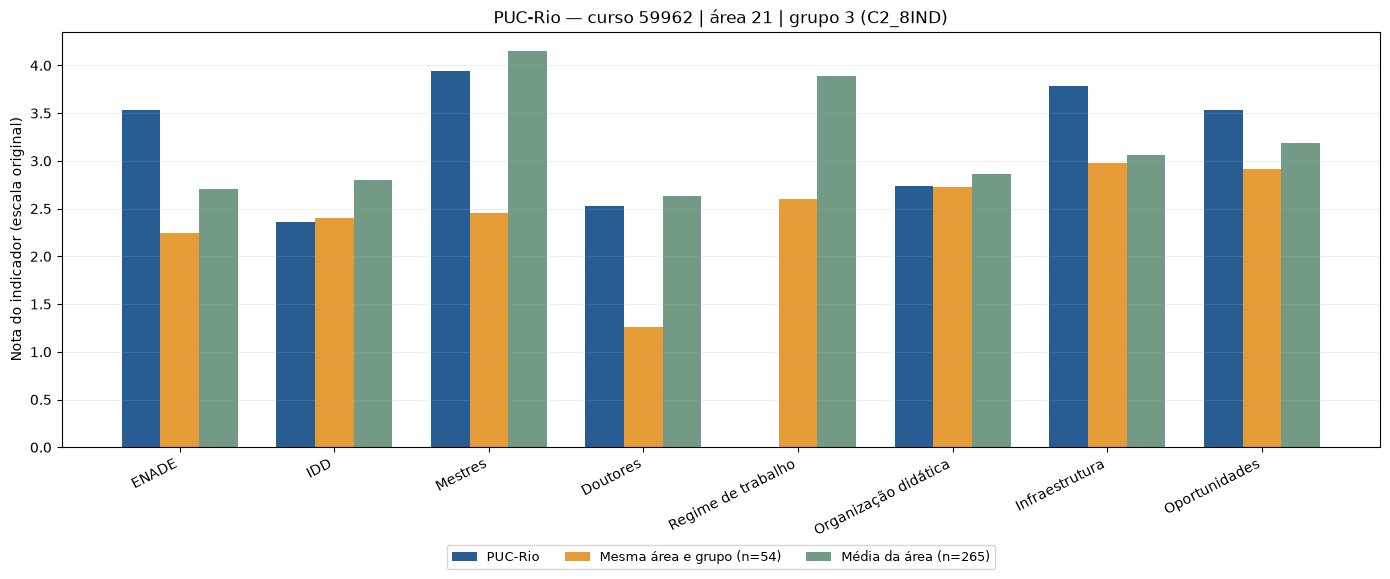

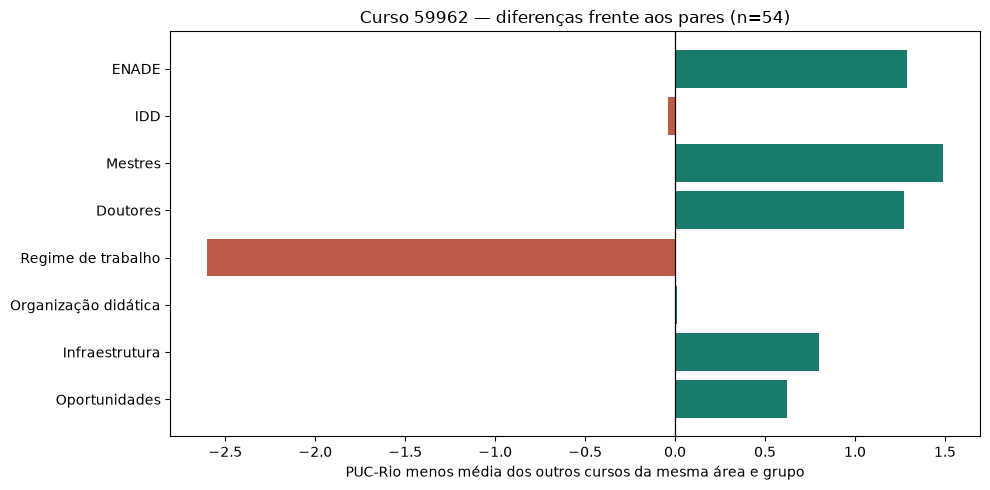

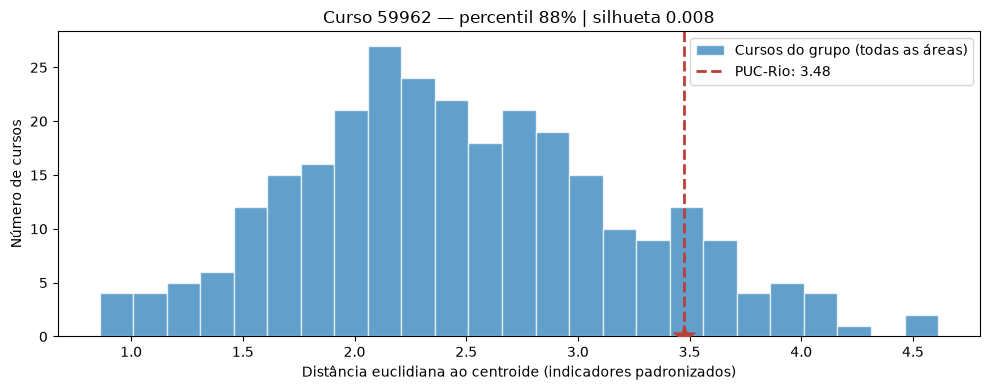

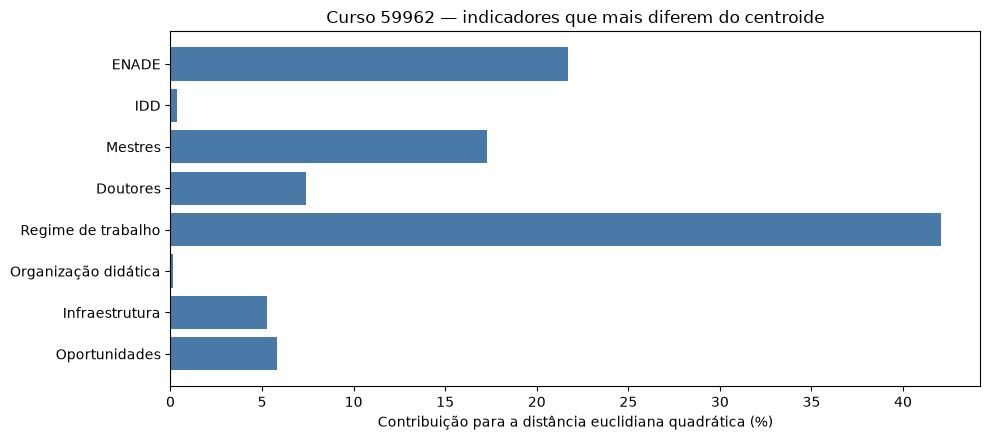

,Indicador,Contribuicao_percentual
4,Regime de trabalho,42.10
0,ENADE,21.70
2,Mestres,17.26
3,Doutores,7.39
7,Oportunidades,5.79
6,Infraestrutura,5.27
1,IDD,0.33
5,Organização didática,0.16


In [7]:
def salvar(fig, nome):
    if SALVAR_FIGURAS:
        fig.savefig(SAIDA / nome, dpi=160, bbox_inches='tight')

def graficos_curso(i, cenario='C2_8IND', exibir=True):
    curso = int(base.loc[i, 'Código do Curso'])
    area = base.loc[i, 'Area_2023']
    r = CENARIOS[cenario]
    grupo = int(r['labels'][i])
    ref, tamanhos = referencias_curso(i, cenario)
    x = np.arange(len(INDICADORES))
    series = ['PUC-Rio', 'Mesma área e grupo', 'Média da área']
    cores = {'PUC-Rio': '#285D94', 'Mesma área e grupo': '#E59B36', 'Média da área': '#729A85'}
    fig, ax = plt.subplots(figsize=(14, 6))
    largura = .25
    for j, s in enumerate(series):
        rotulo = s if s == 'PUC-Rio' else f'{s} (n={tamanhos[s]})'
        ax.bar(x + (j-1)*largura, ref[s].to_numpy(float), width=largura,
               label=rotulo, color=cores[s])
    ax.set_xticks(x, ROTULOS, rotation=27, ha='right')
    ax.set_ylabel('Nota do indicador (escala original)')
    ax.set_ylim(bottom=0)
    ax.set_title(f'PUC-Rio — curso {curso} | área {area} | grupo {grupo} ({cenario})')
    ax.legend(loc='upper center', bbox_to_anchor=(.5, -0.22), ncol=3, fontsize=9)
    ax.grid(axis='y', alpha=.2)
    fig.tight_layout()
    salvar(fig, f'{curso}_{cenario}_01_PUC_vs_pares_area.png')
    if exibir: plt.show()
    plt.close(fig)

    diferenca = (ref['PUC-Rio'] - ref['Mesma área e grupo']).to_numpy(float)
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.barh(ROTULOS, diferenca,
            color=['#197b6c' if np.isfinite(d) and d >= 0 else '#bd5b48' for d in diferenca])
    ax.axvline(0, color='black', lw=.9)
    ax.set_xlabel('PUC-Rio menos média dos outros cursos da mesma área e grupo')
    ax.set_title(f'Curso {curso} — diferenças frente aos pares (n={tamanhos["Mesma área e grupo"]})')
    ax.invert_yaxis()
    fig.tight_layout()
    salvar(fig, f'{curso}_{cenario}_02_diferencas_pares_area.png')
    if exibir: plt.show()
    plt.close(fig)

    dist_grupo = r['dist'][r['labels'] == grupo]
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.hist(dist_grupo, bins=25, alpha=.7, edgecolor='white', label='Cursos do grupo (todas as áreas)')
    ax.axvline(r['dist'][i], color='#bb3f39', ls='--', lw=2,
               label=f'PUC-Rio: {r["dist"][i]:.2f}')
    ax.scatter([r['dist'][i]], [0], marker='*', s=250, color='#bb3f39', zorder=5)
    ax.set_xlabel('Distância euclidiana ao centroide (indicadores padronizados)')
    ax.set_ylabel('Número de cursos')
    ax.set_title(f'Curso {curso} — percentil {r["percentis"][i]:.0f}% | silhueta {r["sil"][i]:.3f}')
    ax.legend()
    fig.tight_layout()
    salvar(fig, f'{curso}_{cenario}_03_distancia_centroide.png')
    if exibir: plt.show()
    plt.close(fig)

    sq = (r['X'][i] - r['modelo'].cluster_centers_[grupo])**2
    contrib = 100*sq/sq.sum() if sq.sum() > 0 else np.zeros_like(sq)
    nomes = ROTULOS if cenario == 'C2_8IND' else list(r['dados'].columns)
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.barh(nomes, contrib, color='#4879a7')
    ax.invert_yaxis()
    ax.set_xlabel('Contribuição para a distância euclidiana quadrática (%)')
    ax.set_title(f'Curso {curso} — indicadores que mais diferem do centroide')
    fig.tight_layout()
    salvar(fig, f'{curso}_{cenario}_04_contribuicao_centroide.png')
    if exibir: plt.show()
    plt.close(fig)
    return pd.DataFrame({'Indicador': nomes, 'Contribuicao_percentual': contrib})

contrib_exemplo = graficos_curso(exemplo, exibir=True)
display(contrib_exemplo.sort_values('Contribuicao_percentual', ascending=False).round(2))


## 8. Exportação das tabelas comparativas para todos os cursos

As duas médias excluem o próprio curso da PUC-Rio. O CSV contém o número de cursos em cada referência e a diferença entre a PUC-Rio e seus pares da mesma área e grupo.


In [8]:
comparacoes = []
contribs = []
pares = []
for nome, r in CENARIOS.items():
    for i in idx_puc:
        curso = int(base.loc[i, 'Código do Curso'])
        ref, ns = referencias_curso(i, nome)
        for ind in INDICADORES:
            comparacoes.append({
                'Cenario': nome, 'Curso_PUC': curso, 'Area_2023': base.loc[i, 'Area_2023'],
                'Grupo': int(r['labels'][i]), 'Indicador': ind,
                'Nota_PUC': ref.loc[ind, 'PUC-Rio'],
                'Media_mesma_area_e_grupo': ref.loc[ind, 'Mesma área e grupo'],
                'Media_area': ref.loc[ind, 'Média da área'],
                'Diferenca_PUC_menos_pares': ref.loc[ind, 'PUC-Rio'] - ref.loc[ind, 'Mesma área e grupo'],
                'N_pares_mesma_area_e_grupo': ns['Mesma área e grupo'],
                'N_outros_cursos_area': ns['Média da área']
            })
        g = r['labels'][i]
        sq = (r['X'][i] - r['modelo'].cluster_centers_[g])**2
        pct = 100*sq/sq.sum() if sq.sum() > 0 else np.zeros_like(sq)
        for indicador, contrib in zip(r['dados'].columns, pct):
            contribs.append({'Cenario': nome, 'Curso_PUC': curso,
                             'Indicador_ou_dimensao': indicador, 'Contribuicao_percentual': contrib})
for i in idx_puc:
    curso = int(base.loc[i, 'Código do Curso'])
    for tipo, mesmo in [('mesma_area_e_grupo', True), ('mesma_area', False)]:
        t = vizinhos(i, mesmo_grupo=mesmo)
        t.insert(0, 'Curso_PUC', curso)
        t.insert(1, 'Tipo_pares', tipo)
        pares.append(t)
pd.DataFrame(comparacoes).to_csv(SAIDA/'comparacao_PUC_pares_mesma_area_e_media_area.csv',
                                index=False, encoding='utf-8-sig')
pd.DataFrame(contribs).to_csv(SAIDA/'contribuicoes_distancia_centroide.csv',
                            index=False, encoding='utf-8-sig')
pd.concat(pares, ignore_index=True).to_csv(SAIDA/'vizinhos_PUCRio_C2.csv',
                                         index=False, encoding='utf-8-sig')
print('Exportadas', len(comparacoes), 'linhas de comparação.')
display(pd.DataFrame(comparacoes).query('Cenario == "C2_8IND"').head(8).round(3))


Exportadas 128 linhas de comparação.


,Cenario,Curso_PUC,Area_2023,Grupo,Indicador,Nota_PUC,Media_mesma_area_e_grupo,Media_area,Diferenca_PUC_menos_pares,N_pares_mesma_area_e_grupo,N_outros_cursos_area
0,C2_8IND,59962,21,3,Enade_2023,3.531,2.242,2.707,1.289,54,265
1,C2_8IND,59962,21,3,IDD_2023,2.358,2.396,2.801,-0.038,54,265
2,C2_8IND,59962,21,3,Mestres_2023,3.941,2.451,4.148,1.490,54,265
3,C2_8IND,59962,21,3,Doutores_2023,2.529,1.258,2.629,1.271,54,265
4,C2_8IND,59962,21,3,Regime_Trabalho_2023,0.000,2.600,3.887,-2.600,54,265
5,C2_8IND,59962,21,3,Organizacao_Didatica_2023,2.734,2.724,2.859,0.010,54,265
6,C2_8IND,59962,21,3,Infraestrutura_2023,3.780,2.981,3.060,0.799,54,265
7,C2_8IND,59962,21,3,Oportunidades_2023,3.537,2.918,3.190,0.619,54,265


## 9. Gerar automaticamente os gráficos para **cada curso da PUC-Rio**

Por padrão, os gráficos são exportados para **todos os cursos da PUC-Rio no C2**. A visualização na tela é opcional, para evitar dezenas de figuras durante a execução. Para também gerar o C3, acrescente `'C3_4DIM'` à lista.


Gerando gráficos: C2_8IND, curso 59962, área 21, pares da mesma área e grupo = 54


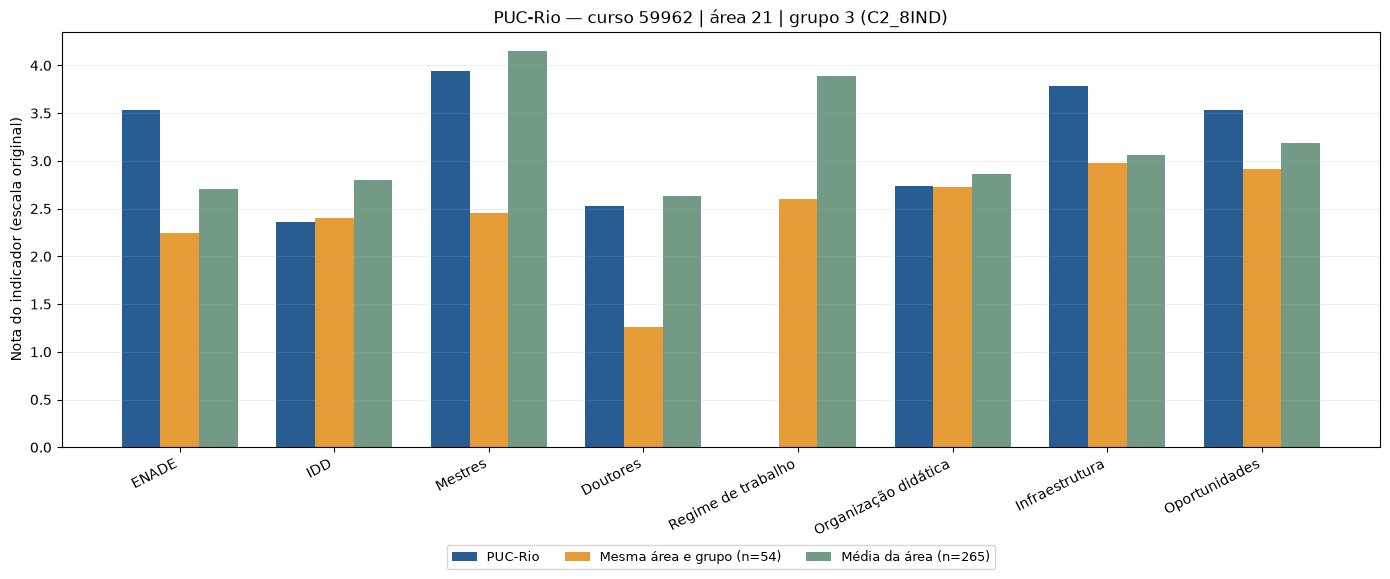

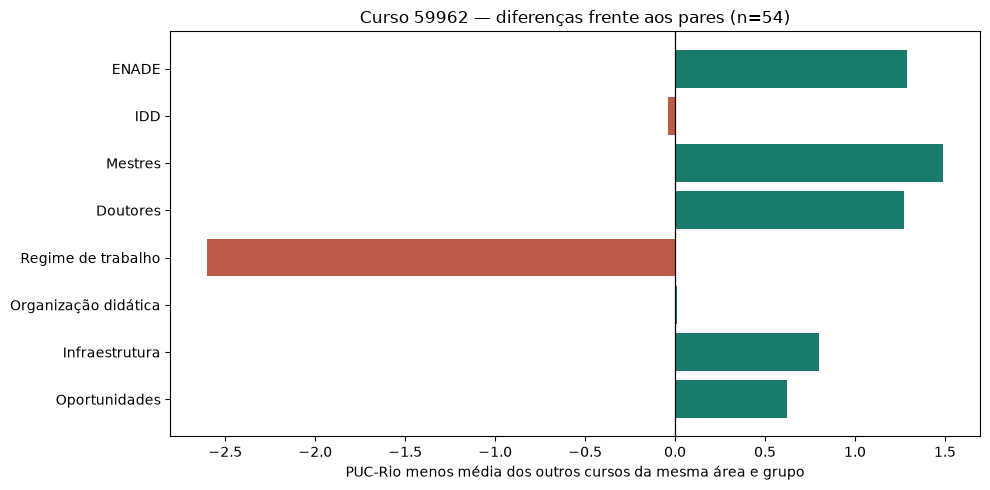

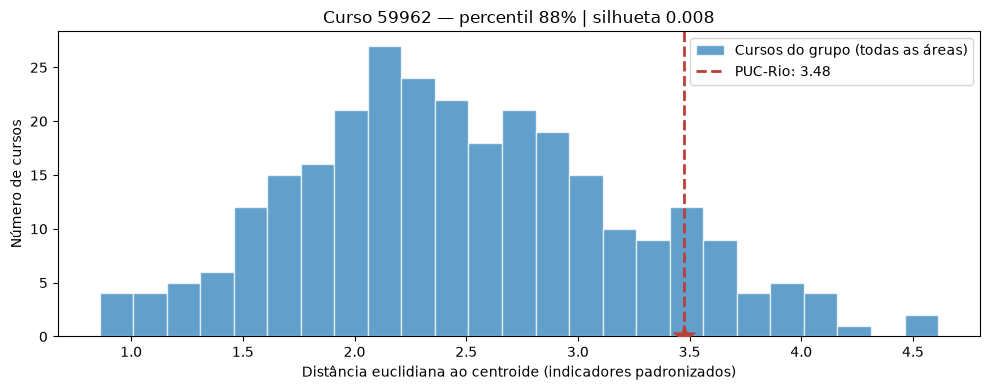

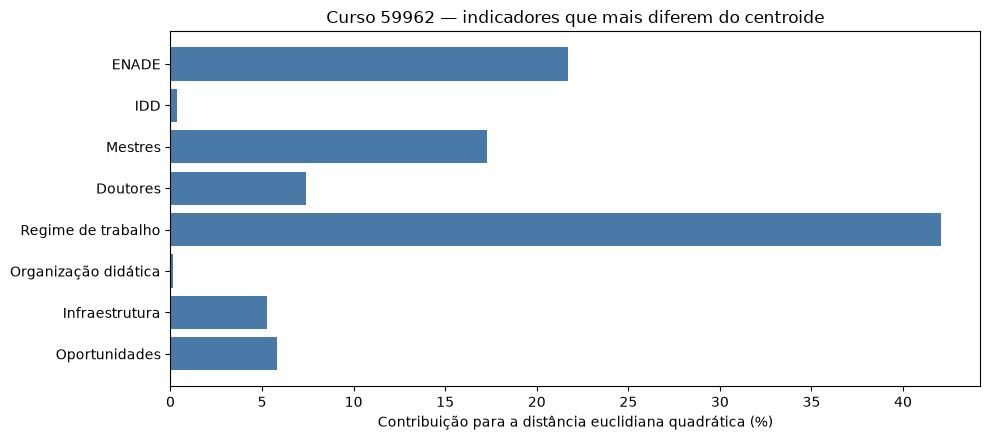

Gerando gráficos: C2_8IND, curso 29445, área 5710, pares da mesma área e grupo = 84


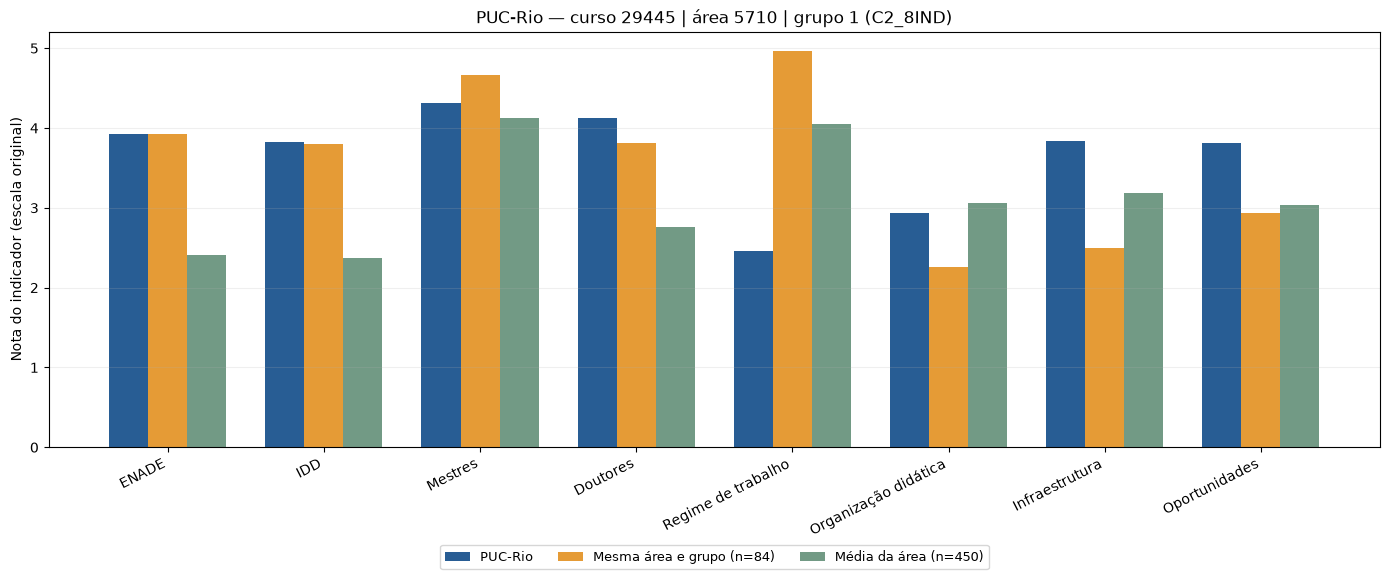

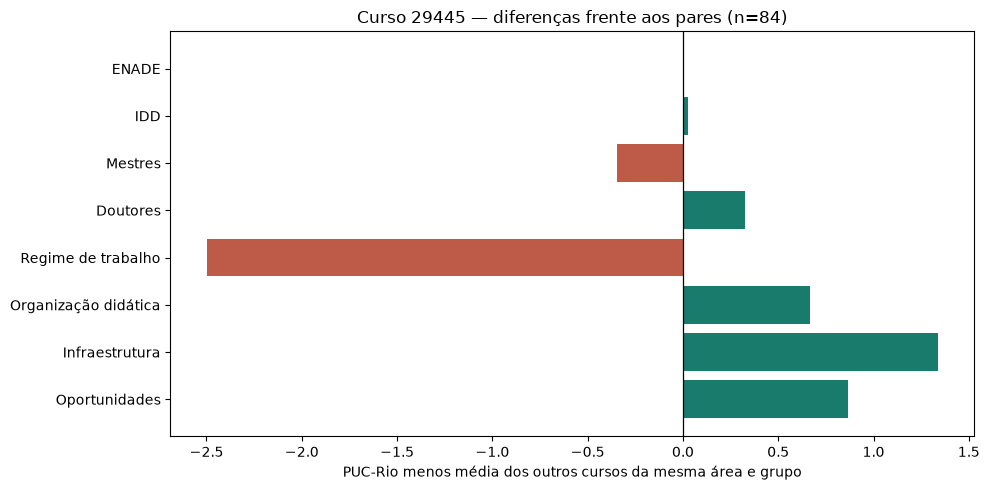

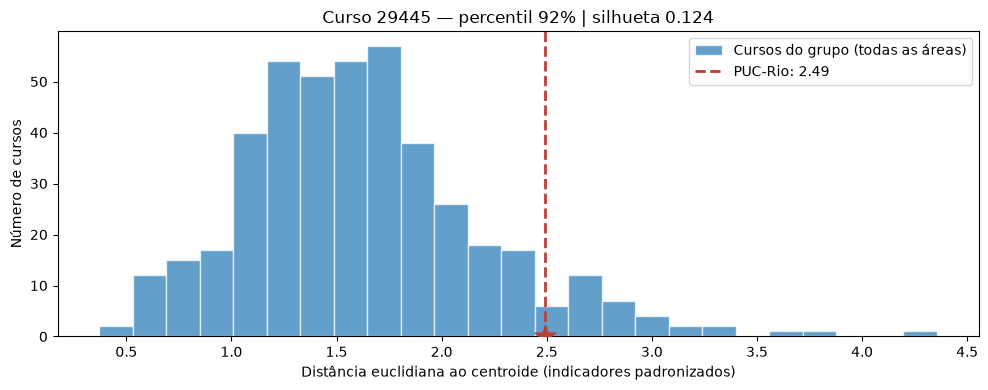

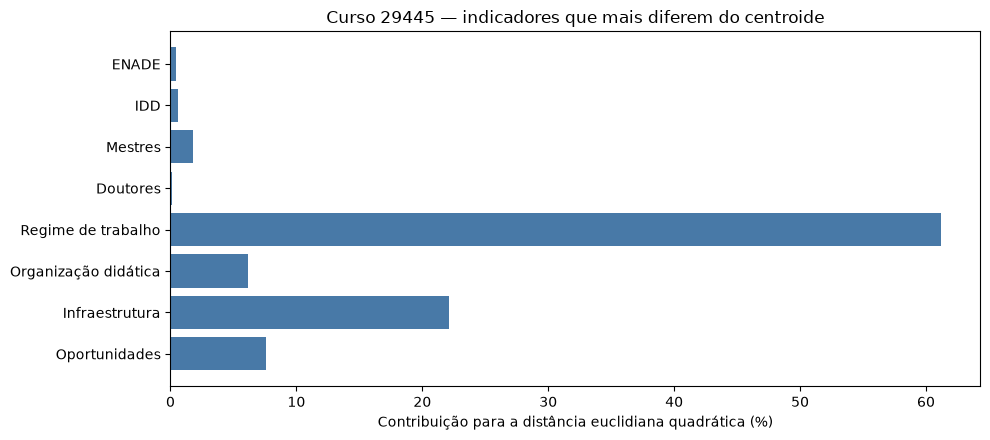

Gerando gráficos: C2_8IND, curso 29446, área 5806, pares da mesma área e grupo = 73


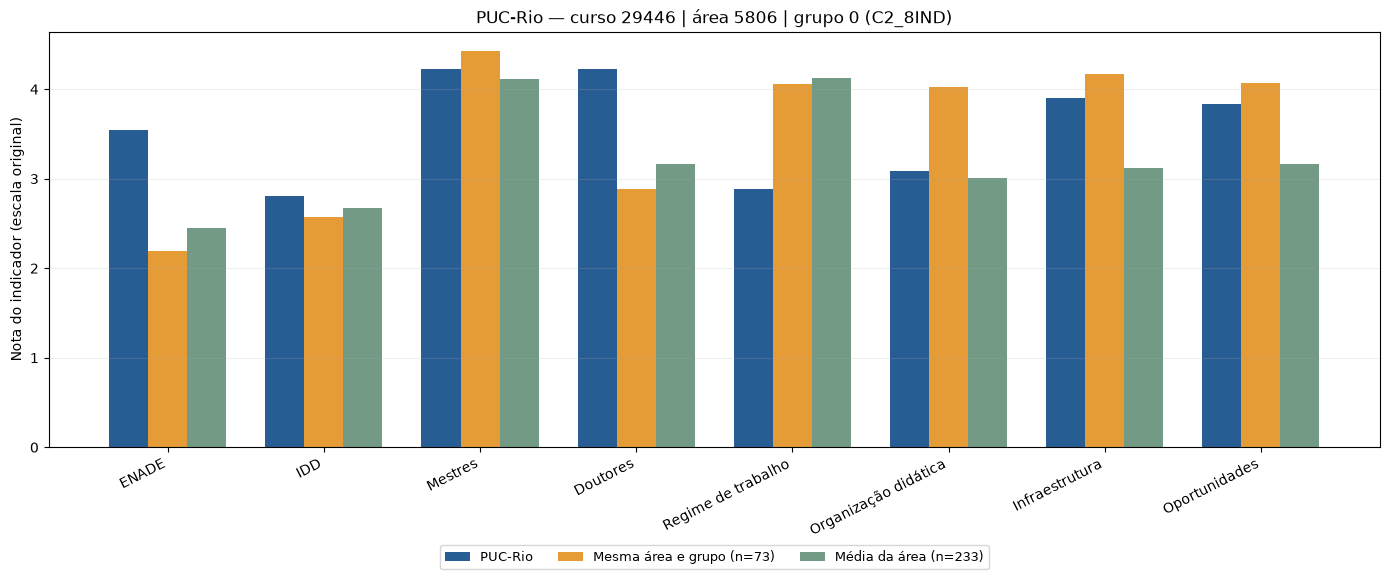

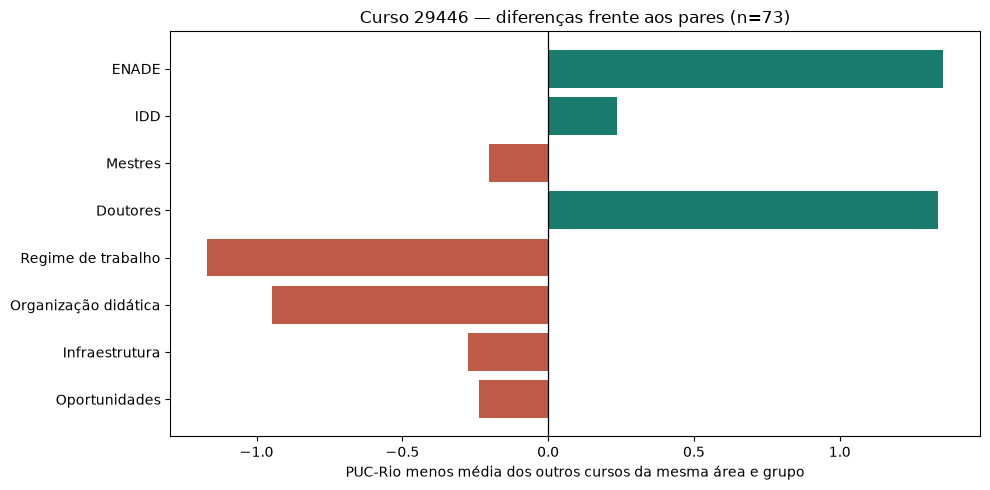

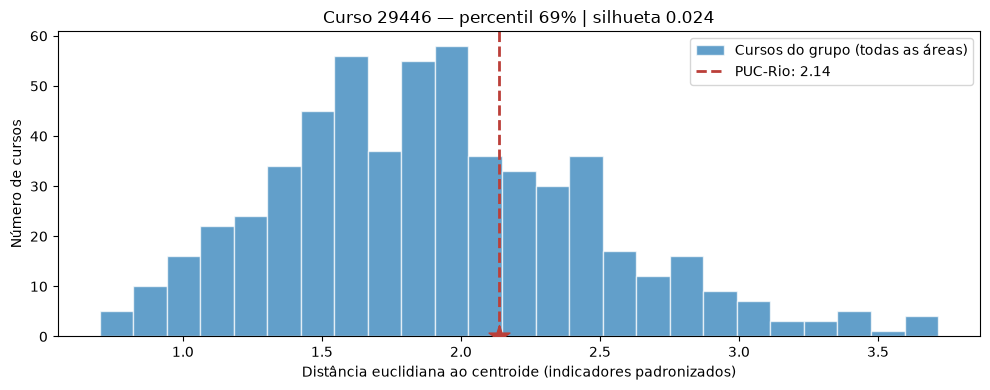

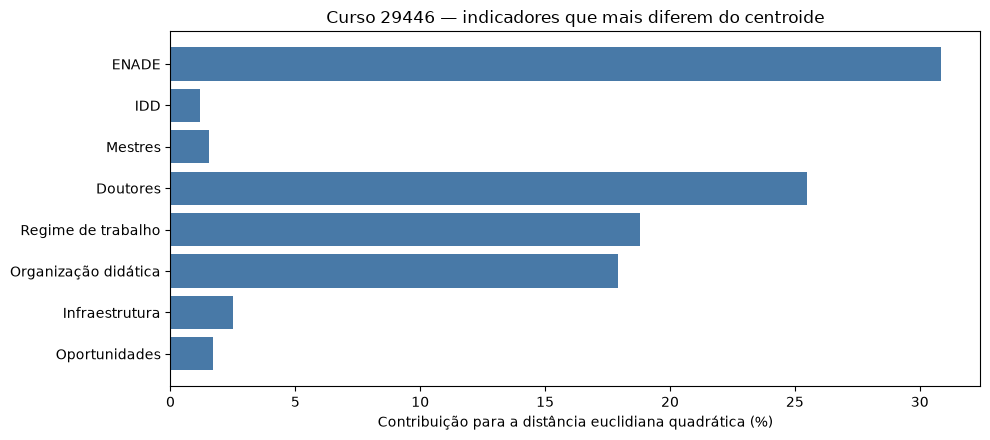

Gerando gráficos: C2_8IND, curso 32655, área 5814, pares da mesma área e grupo = 39


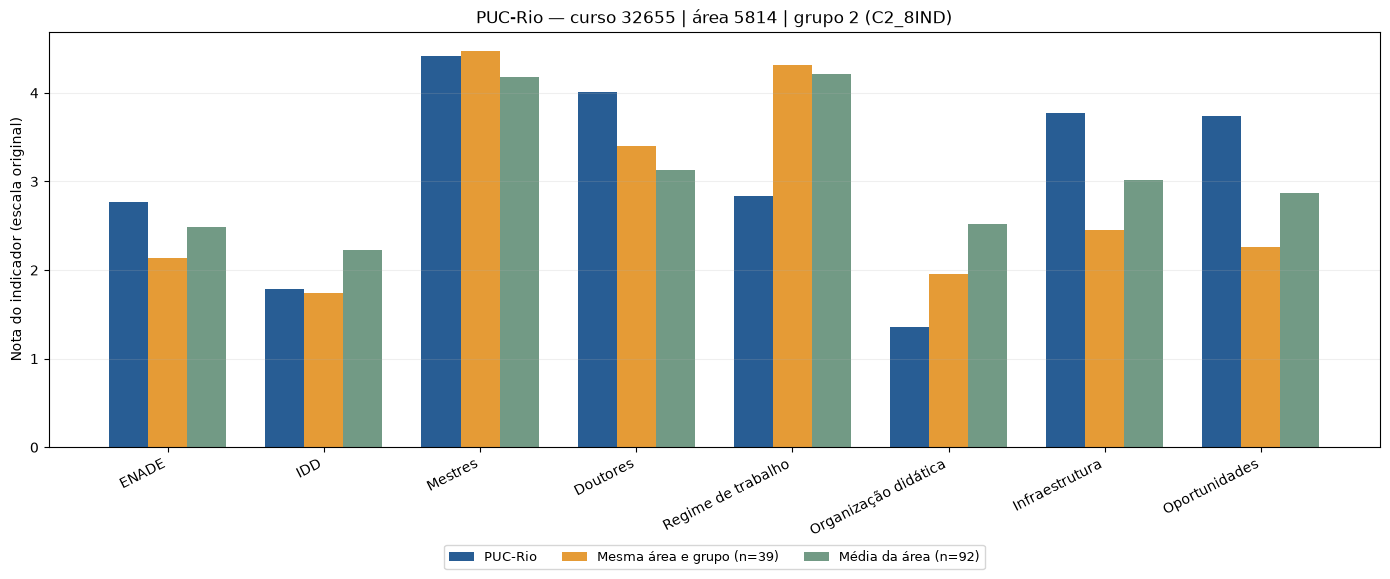

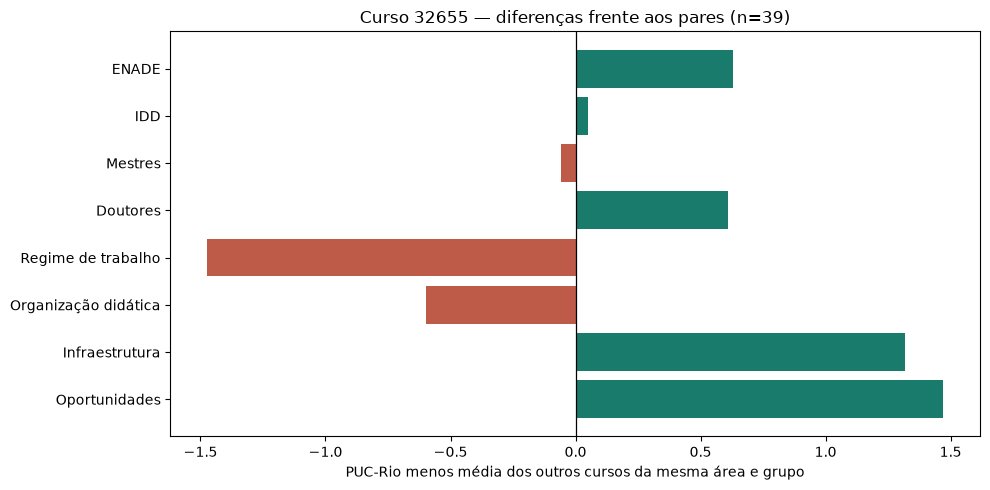

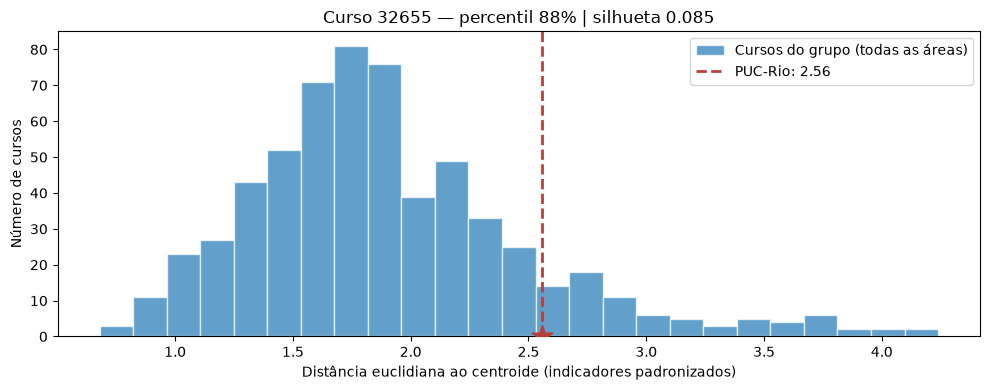

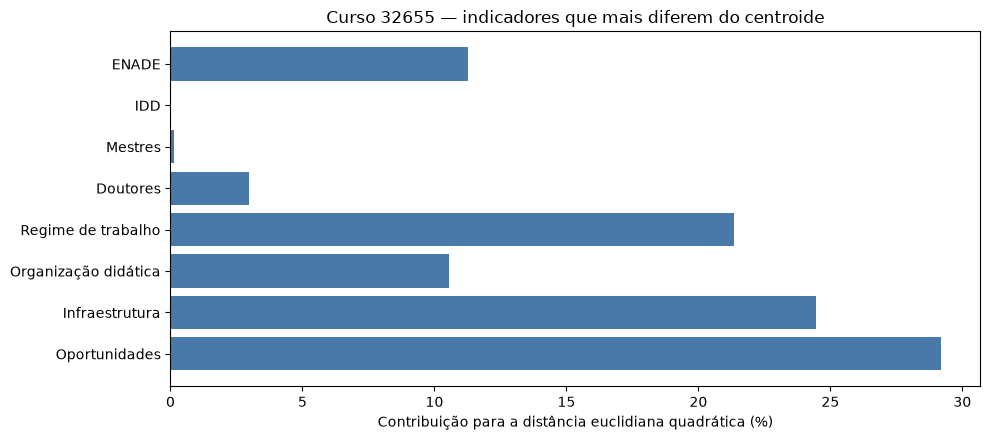

Gerando gráficos: C2_8IND, curso 23702, área 5902, pares da mesma área e grupo = 61


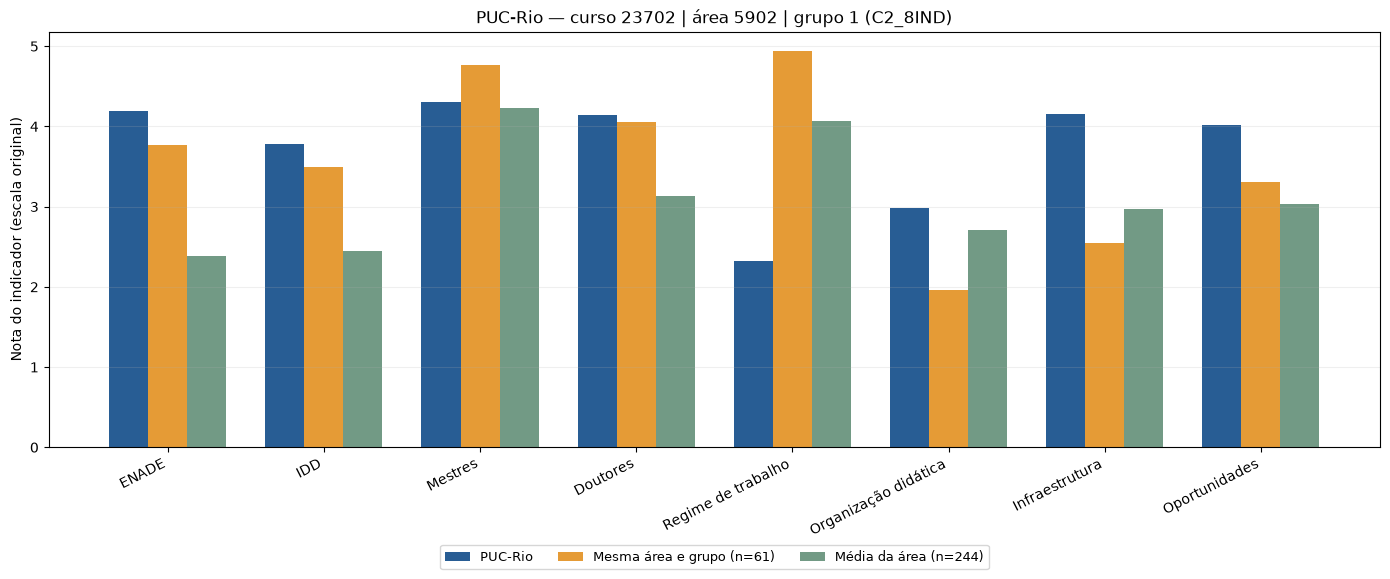

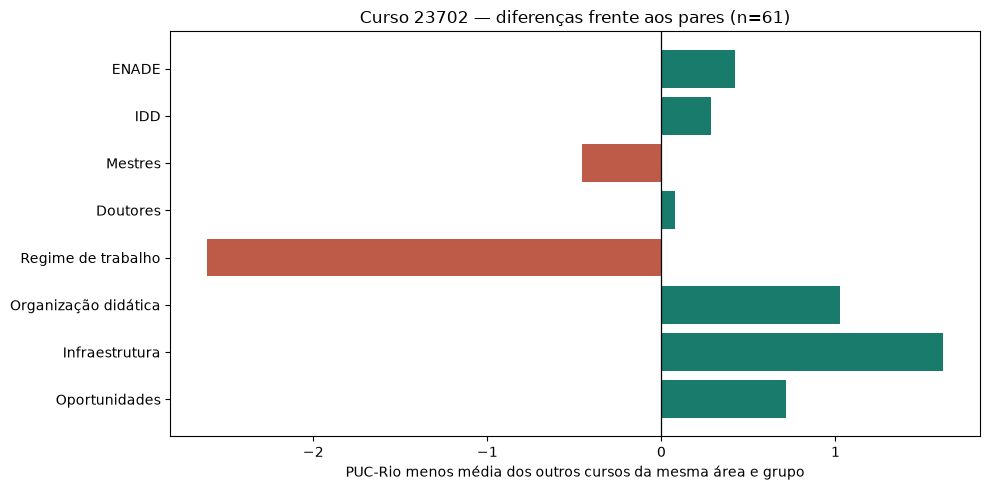

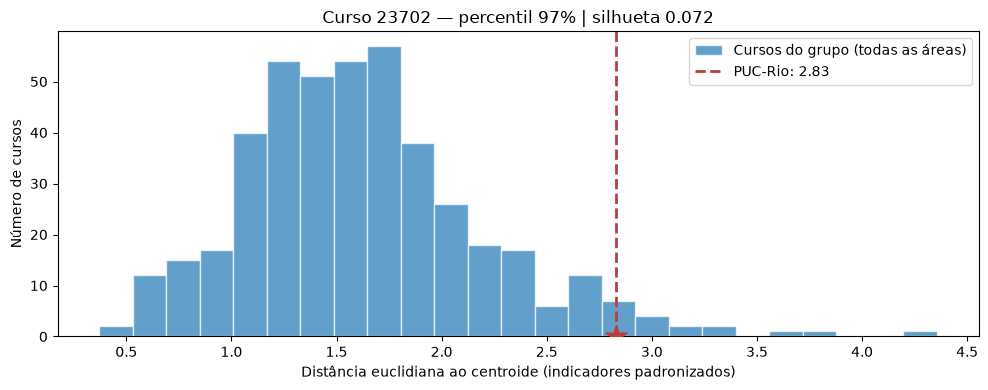

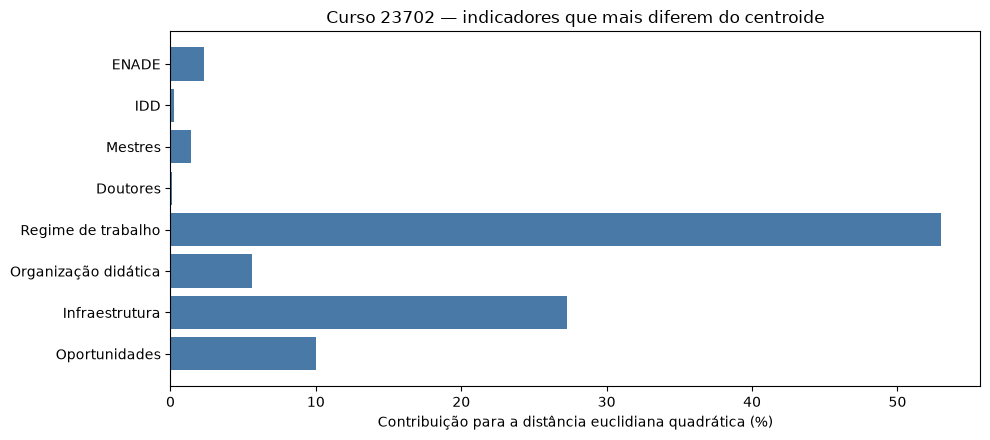

Gerando gráficos: C2_8IND, curso 32975, área 6008, pares da mesma área e grupo = 24


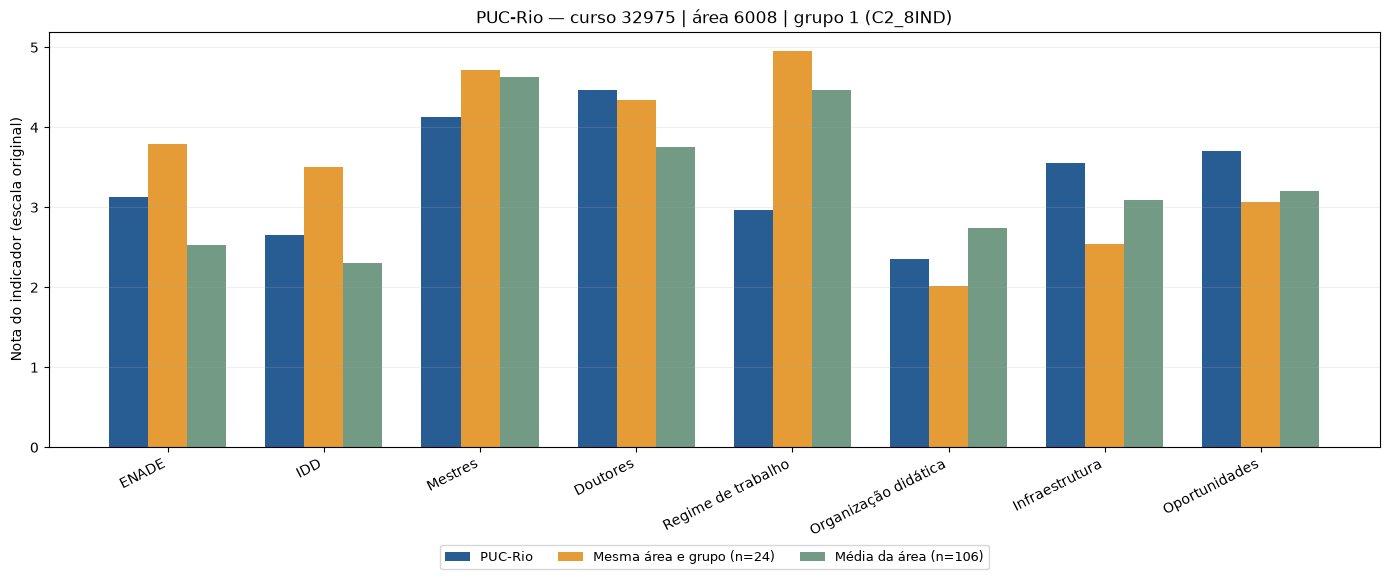

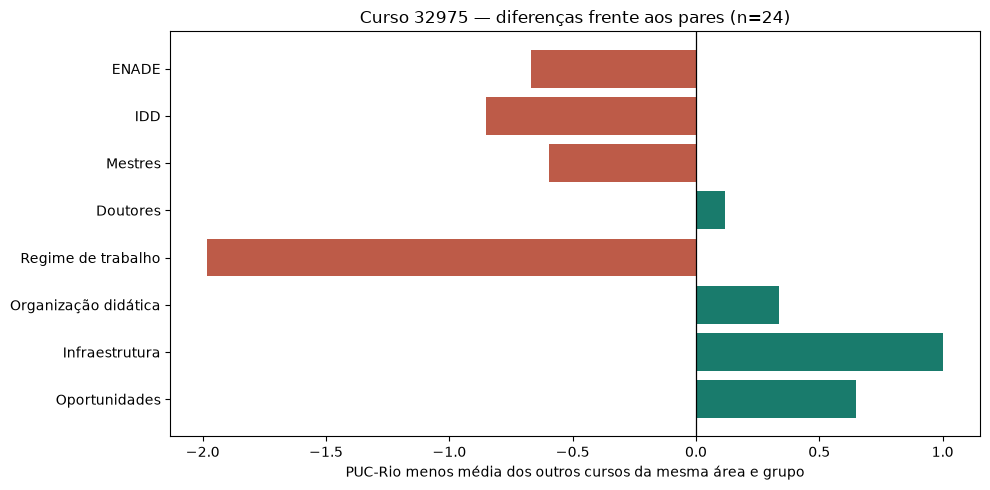

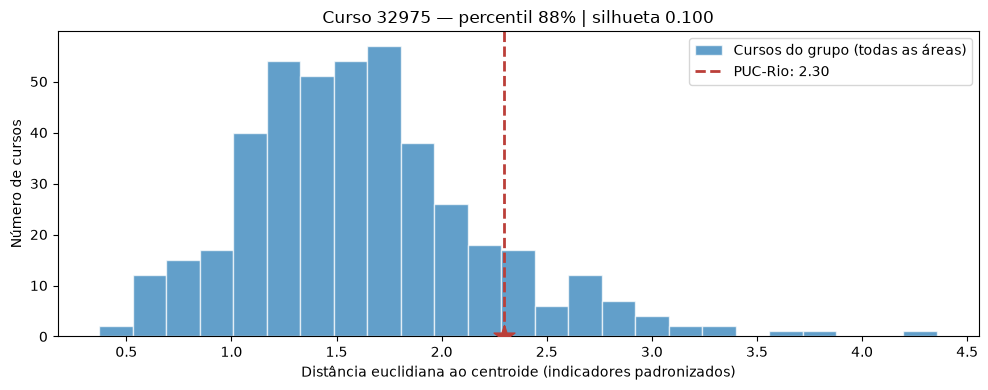

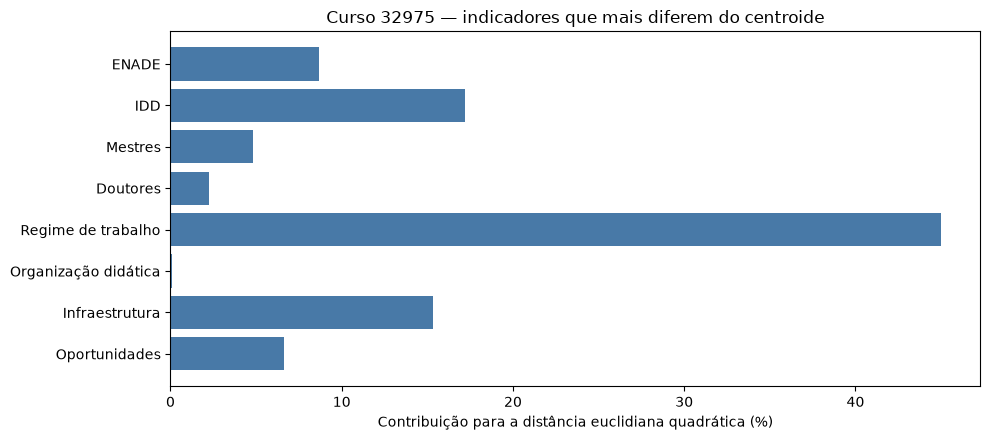

Gerando gráficos: C2_8IND, curso 44431, área 6208, pares da mesma área e grupo = 110


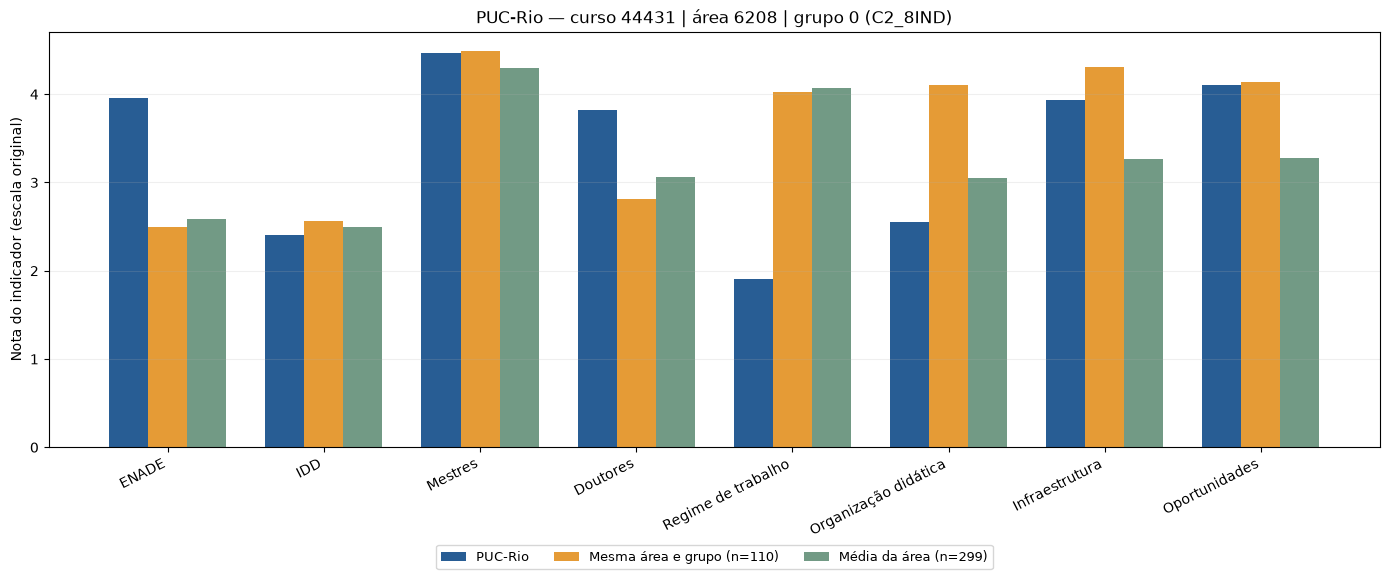

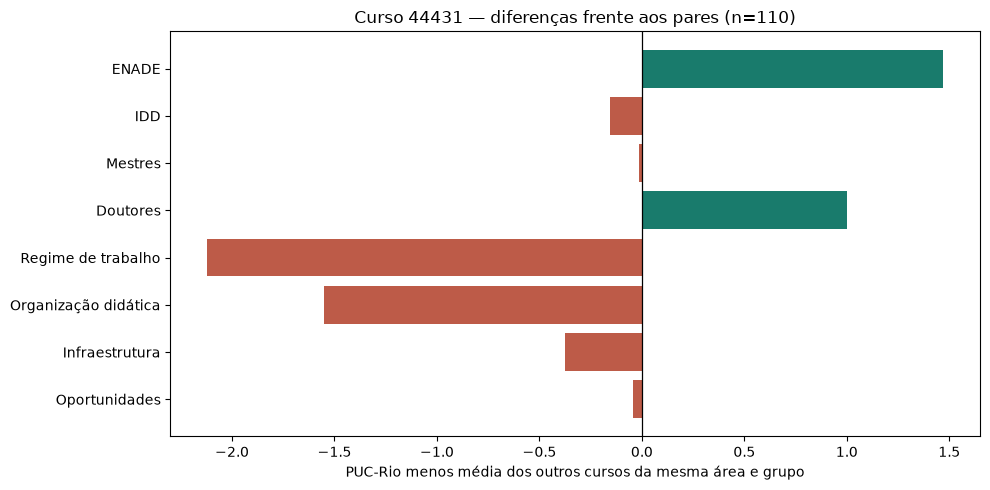

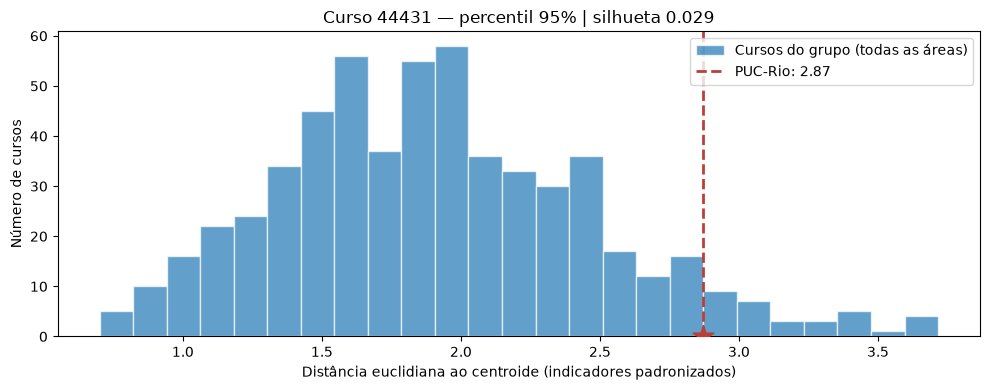

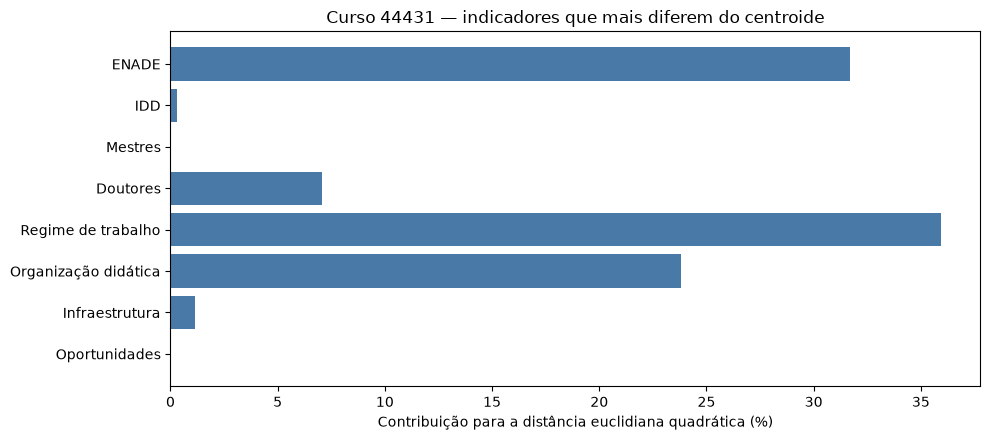

Gerando gráficos: C2_8IND, curso 70523, área 6307, pares da mesma área e grupo = 36


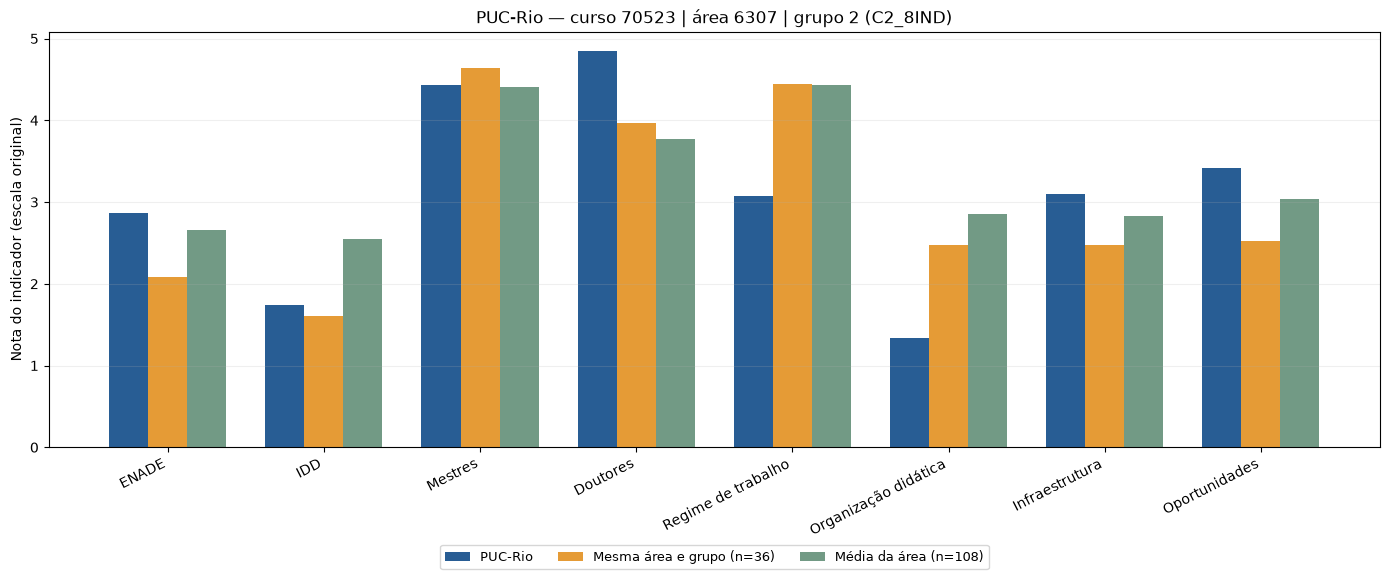

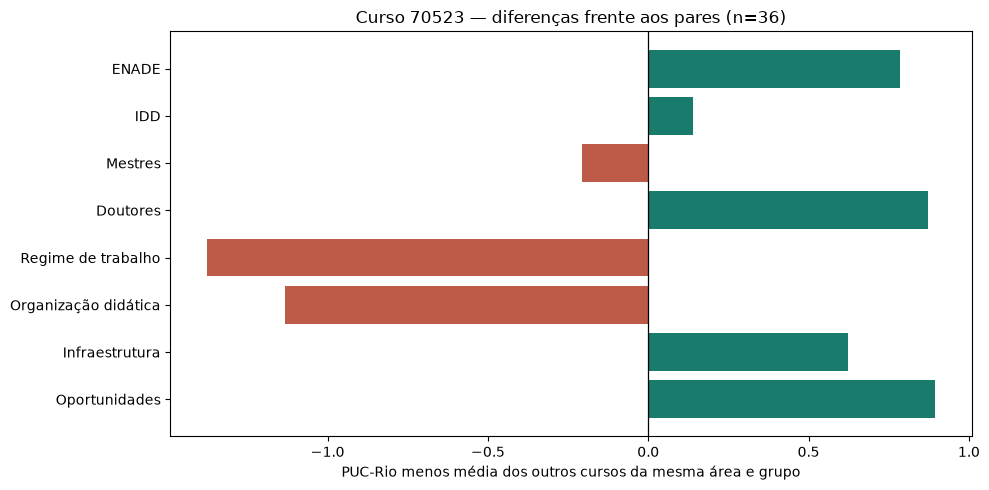

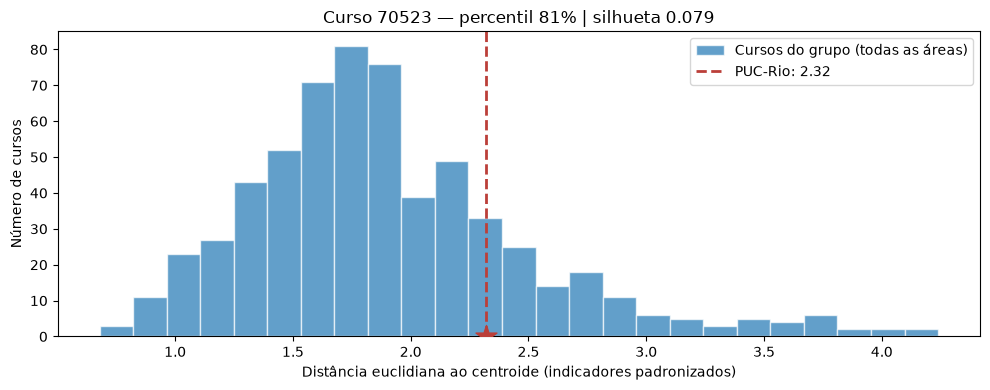

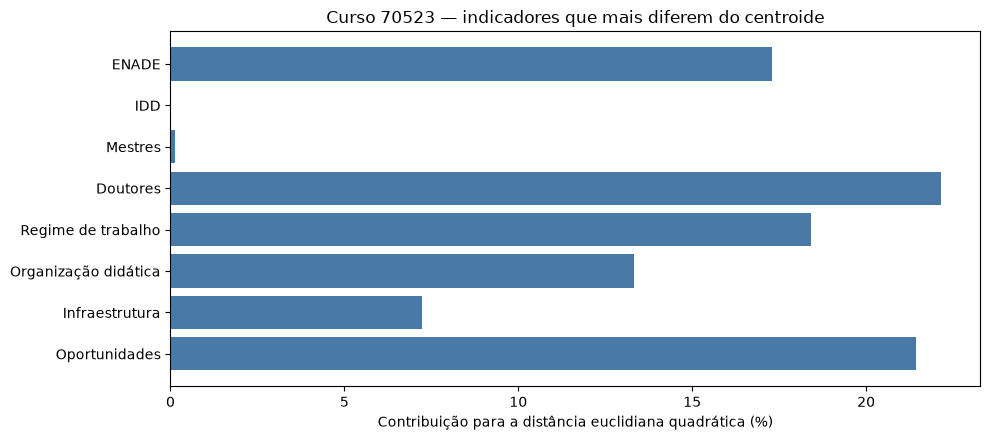

Gráficos exportados em: g:\Meu Drive\Mestrado _ Eng_Ind\IND2622 - Ciencia de dados para processos de negocios\Trabalho final - CPC (escolhido)\Projeto_CPC_PUC_Rio_2026\resultados_notebook_06\BASE_COMPLETA


In [9]:
CENARIOS_PARA_GRAFICOS = ['C2_8IND']
EXIBIR_GRAFICOS_DE_TODOS = True
for nome in CENARIOS_PARA_GRAFICOS:
    for i in idx_puc:
        curso = int(base.loc[i, 'Código do Curso'])
        _, ns = referencias_curso(i, nome)
        print(f'Gerando gráficos: {nome}, curso {curso}, área {base.loc[i, "Area_2023"]}, '
              f'pares da mesma área e grupo = {ns["Mesma área e grupo"]}')
        graficos_curso(i, nome, exibir=EXIBIR_GRAFICOS_DE_TODOS)
print('Gráficos exportados em:', SAIDA)


## 10. Checagem de estabilidade por reamostragem (C2 e C3, K=4)
Para cada uma de 30 divisões 80/20, ajustamos o modelo apenas no treino e **atribuímos rótulos aos 1.907 cursos**. O Jaccard compara o conjunto de **outros** cursos que acompanham cada curso da PUC-Rio. Também calculamos silhueta e percentil de distância **em cada modelo, no mesmo universo**, como análise descritiva. Isso não constitui teste externo independente. O valor mínimo de Jaccard pode ser muito sensível a uma divisão excepcional.

In [10]:
from sklearn.model_selection import train_test_split
from itertools import combinations
from sklearn.metrics import adjusted_rand_score

historico=[];jaccards=[];particoes={}
for nome in CENARIOS:
    D=representar(base,nome).to_numpy(float)
    particoes[nome]={}
    for seed in range(42,42+REPETICOES):
        ids_treino,_=train_test_split(np.arange(len(base)),test_size=.2,random_state=seed)
        scaler=StandardScaler().fit(D[ids_treino])
        X=scaler.transform(D)
        modelo=KMeans(n_clusters=K,n_init=N_INIT,random_state=SEMENTE).fit(X[ids_treino])
        labels=modelo.predict(X)
        particoes[nome][seed]=labels
        sil=silhouette_samples(X,labels)
        dist=np.linalg.norm(X-modelo.cluster_centers_[labels],axis=1)
        for i in idx_puc:
            ix=np.flatnonzero(labels==labels[i]); pct=100*(np.sum(dist[ix]<dist[i])+.5*np.sum(dist[ix]==dist[i]))/len(ix)
            historico.append({'Cenario':nome,'Seed':seed,'Curso_PUC':int(base.loc[i,'Código do Curso']),
                              'Grupo':int(labels[i]),'Silhueta_individual':float(sil[i]),
                              'Percentil_distancia':float(pct)})
    for i in idx_puc:
        valores=[]
        for s1,s2 in combinations(particoes[nome],2):
            a=particoes[nome][s1]==particoes[nome][s1][i]
            b=particoes[nome][s2]==particoes[nome][s2][i]
            a=a.copy();b=b.copy();a[i]=False;b[i]=False
            inter=np.sum(a&b);uniao=np.sum(a|b)
            valores.append(inter/uniao if uniao else 1.0)
        jaccards.append({'Cenario':nome,'Curso_PUC':int(base.loc[i,'Código do Curso']),
                         'Jaccard_medio':np.mean(valores),'Jaccard_minimo':np.min(valores)})
historico=pd.DataFrame(historico);jaccards=pd.DataFrame(jaccards)
resumo_individual=historico.groupby(['Cenario','Curso_PUC'],as_index=False).agg(
    Silhueta_media=('Silhueta_individual','mean'),Silhueta_min=('Silhueta_individual','min'),
    Percentil_distancia_medio=('Percentil_distancia','mean'),Percentil_distancia_max=('Percentil_distancia','max'))
resumo_individual=resumo_individual.merge(jaccards,on=['Cenario','Curso_PUC'])
historico.to_csv(SAIDA/'metricas_individuais_30_divisoes.csv',index=False,encoding='utf-8-sig')
resumo_individual.to_csv(SAIDA/'resumo_estabilidade_individual.csv',index=False,encoding='utf-8-sig')
display(resumo_individual.round(3))

,Cenario,Curso_PUC,Silhueta_media,Silhueta_min,Percentil_distancia_medio,Percentil_distancia_max,Jaccard_medio,Jaccard_minimo
0,C2_8IND,23702,0.074,0.064,96.554,97.398,0.983,0.945
1,C2_8IND,29445,0.126,0.117,92.156,92.792,0.983,0.945
2,C2_8IND,29446,0.022,0.012,69.446,71.847,0.972,0.920
3,C2_8IND,32655,0.082,0.069,87.614,88.269,0.972,0.928
4,C2_8IND,32975,0.100,0.097,88.086,89.492,0.983,0.945
5,C2_8IND,44431,0.027,0.021,94.233,95.293,0.972,0.920
6,C2_8IND,59962,0.019,-0.003,87.499,91.840,0.944,0.873
7,C2_8IND,70523,0.077,0.065,80.731,82.619,0.972,0.928
8,C3_4DIM,23702,0.299,0.287,55.230,58.188,0.982,0.945
9,C3_4DIM,29445,0.326,0.312,35.769,40.066,0.982,0.945


## 11. Interpretação e limites

- O **grupo** é definido pelo K-means ajustado à **base completa** (C2, K=4).
- A referência de **pares** é composta exclusivamente pelos **outros cursos da mesma área e do mesmo grupo** da PUC-Rio.
- A **média da área** usa os outros cursos da mesma área, independentemente do grupo.
- Os gráficos comparativos mostram os oito indicadores na escala original. O próprio curso da PUC-Rio é excluído das médias.
- A distância ao centroide e sua decomposição são calculadas no espaço padronizado do cenário, e o grupo pode conter cursos de outras áreas. Isso é intencional: o centroide descreve o modelo global, enquanto as médias do gráfico principal descrevem os pares da mesma área.
- Silhueta individual baixa ou percentil de distância elevado indicam que a média dos pares deve ser interpretada com cautela.
- Os indicadores correlacionados podem receber maior influência implícita no C2.
- O C3 é uma análise de robustez, não substitui automaticamente o C2.
- Trata-se de diagnóstico exploratório, não de explicação causal nem de ranking de qualidade.
